# PartB - World map of glacier model differences

One subplot per RGI region (and Global). The figure should answer one question: **how much do the glacier models differ?** Two versions:
- `y80`: **left** mass after 80 simulation years, **right** steady-state mass (both mass remaining in % of 2020, one shared y-axis)
- `tau`: **left** steady-state mass, **right** response timescale (80% of the total change, not shifted to 2020)

Two subplot styles:
- `range` (default): per plot one bar = range of the four global models, a black line = their median, and the number = median glacier model difference
- `dots`: all models as dots (four global models as circles, regional models as diamonds)

In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch, Rectangle
import cartopy
import cartopy.crs as ccrs
from cartopy.io.shapereader import Reader
from cartopy.feature import ShapelyFeature

In [2]:
plt.rcParams["pdf.use14corefonts"] = False  # don't convert text to path
plt.rcParams['pdf.fonttype'] = 42  # keep the text editable in the pdf

## Settings

In [3]:
# which versions of the figure and which values?
variants = ['y80', 'tau']     # 'y80': 80 years | steady state,  'tau': steady state | response timescale
modes = ['abs', 'diff']       # 'abs': absolute values,  'diff': difference to the median of the four global models
subplot_style = 'range'         # 'range': bar (total range of the four global models' medians), 'dots': all models as dots
also_dots = True              # also make the version with all glacier models as dots 

# data (change to your local paths), created in PartB_3 and PartB_2
fn_steady_state = 'PartB_data/steady_state_relative_volume_change.csv'
fn_after80 = 'PartB_data/after80yrs_relative_volume_change.csv'
fn_resp_time = 'PartB_data/resp_time_non_shifted_for_deltaT_rgi_reg_roll_volume_area_21yravg.csv'

temp_bin = [2.0, 4.0]         # global warming bin in °C
show_numbers = False          # 'Alaska (01)' or just 'Alaska'  (CL: False, the names must fit into the 2 cm wide boxes)

add_rgi_regions = True       # outlines of the RGI regions, see Attention below
add_rgi_glaciers = True      # grey dots for all RGI glaciers, see Attention below

fig_dir = 'figures_partB/worldmap_fig1/'
os.makedirs(fig_dir, exist_ok=True)

**Attention:** to add the RGI region outlines and the glacier dots as in the GMIP3-comm worldmap (`4_world_map_figure...ipynb`), you need `rgi60_regions_robinson-v2.shp` from `GlacierMIP3/data/data_from_others` and the RGI stats file. Set `add_rgi_regions` and `add_rgi_glaciers` to True and adapt the paths:

In [4]:
rgi_regions_fn = '../data/data_from_others/rgi60_regions_robinson-v2.shp'
# only needed if add_rgi_glaciers = True (as in the GMIP3-comm notebook: df_rgi6g with 'CenLon', 'CenLat')
if add_rgi_glaciers:
    from oggm import utils
    df_rgi6g = pd.read_hdf(utils.file_downloader('https://cluster.klima.uni-bremen.de/~oggm/rgi/rgi62_stats.h5'))
    df_rgi6g = df_rgi6g.loc[df_rgi6g.Connect != 2]

## Names, colours and positions

In [5]:
# names of the RGI regions (could also be taken from d_reg_num_name in help_functions)
reg_names = {'All': 'Global', '01': 'Alaska', '02': 'W Canada & US', '03': 'Arctic Canada N', '04': 'Arctic Canada S',
             '05': 'Greenland Periphery', '06': 'Iceland', '07': 'Svalbard & Jan Mayen', '08': 'Scandinavia',
             '09': 'Russian Arctic', '10': 'North Asia', '11': 'Central Europe', '12': 'Caucasus & Middle East',
             '13': 'Central Asia', '14': 'South Asia W', '15': 'South Asia E', '16': 'Low Latitudes',
             '17': 'Southern Andes', '18': 'New Zealand', '19': 'Subantarctic & Antarctic Islands'}

# names with a line break where a name is long (the number is added in the title of the subplot)
reg_names_lines = dict(reg_names)
reg_names_lines.update({'05': 'Greenland\nPeriphery', '07': 'Svalbard &\nJan Mayen',
                        '12': 'Caucasus &\nMiddle East',
                        '19': 'Subantarctic &\nAntarctic Islands'})

# glacier models: the four global models are in the median, the regional models are only shown (style 'dots')
global_models = ['PyGEM-OGGM', 'GloGEMflow', 'OGGM', 'GLIMB']
regional_models = ['GloGEMflow3D', 'Kraaijenbrink', 'GO', 'CISM2']
model_names_csv = {'PyGEM-OGGM_v13': 'PyGEM-OGGM', 'OGGM_v16': 'OGGM'}   # names in the csv files, all others are the same

# colours as in the model difference figures (could be replaced by pal_models from help_functions)
dict_model_col = {'PyGEM-OGGM': '#5fb0e1', 'GloGEMflow': '#d18c14', 'OGGM': '#ca79bc', 'GLIMB': '#fab1e5',
                  'GloGEMflow3D': '#0f9373', 'Kraaijenbrink': '#c46011', 'GO': '#e5d73d', 'CISM2': '#562e10'}
col_80, col_ss, col_tau = '#2a7f7f', '#3b4a6b', '#b5532a'

# point where the line to the region ends (lon, lat)
# TODO: the lon/lat points are only approximate, could be replaced by the centres of the RGI regions
reg_lonlat = {'01': [-145, 62], '02': [-121, 52], '03': [-80, 80], '04': [-70, 68], '05': [-40, 70], '06': [-18, 64.8],
              '07': [16, 78], '08': [16, 67.5], '09': [70, 75], '10': [150, 60], '11': [10, 46.5], '12': [44, 43],
              '13': [80, 42], '14': [74, 35.5], '15': [90, 29], '16': [-75, -5], '17': [-72, -45], '18': [170.5, -43.5],
              '19': [-37, -54.5]}

# CL: line breaks so that the titles fit into the 2 cm wide boxes at 6.5 pt (the RGI numbers are not shown, see show_numbers)
reg_names_lines.update({'02': 'W Canada\n& US', '03': 'Arctic\nCanada N', '04': 'Arctic\nCanada S', '09': 'Russian\nArctic',
                        '10': 'North\nAsia', '11': 'Central\nEurope', '13': 'Central\nAsia', '14': 'South\nAsia W',
                        '15': 'South\nAsia E', '16': 'Low\nLatitudes', '17': 'Southern\nAndes', '18': 'New\nZealand'})

# CL: the figure is created at its PRINTED size (two-column figure of The Cryosphere, include it with width=17cm),
# so all font sizes, line widths and marker sizes in the plotting functions are the printed sizes (pt).
# Smallest font size: 6 pt (published TC figures: typically ~5 to 7.5 pt; the captions are 9 pt).
fig_w_cm = 17.0
map_h_cm = fig_w_cm / 1.9716            # aspect ratio of the global Robinson map
top_strip_cm = 1.95                     # white strip above the map for the first row of regional boxes
fig_h_cm = map_h_cm + top_strip_cm      # 17 x 10.6 cm
box_w_cm, box_h_cm = 2.0, 1.8           # regional boxes
glob_rect_cm = (0.10, 0.10, 4.70, 4.35) # Global box with legend: x0, y0, width, height

# CL: centre of each regional box in cm from the lower left corner of the figure (replaces subplot_pos in figure fractions);
# first row above the map (y = 9.6 cm), the other boxes over oceans/areas without glaciers; checked for overlaps
box_pos_cm = {'01': (1.05, 9.6), '04': (3.15, 9.6), '03': (5.25, 9.6), '05': (7.35, 9.6), '07': (9.45, 9.6),
              '08': (11.55, 9.6), '09': (13.65, 9.6), '10': (15.75, 9.6),
              '02': (1.25, 6.95), '16': (3.35, 5.50), '06': (6.70, 6.50), '11': (6.90, 4.40), '12': (9.10, 4.60),
              '13': (13.00, 7.45), '14': (11.20, 3.50), '15': (13.40, 4.40), '17': (7.60, 2.40),
              '19': (9.90, 1.30), '18': (14.00, 1.40)}

## 1. Prepare the data

Everything is computed from the raw columns of the csv files for the temperature bin 2.0°C to 4.0°C (31 climate scenarios), with the **median of the four global models** as reference ((two steps: median over the four models for each scenario, then median over the 31 scenarios; only the delta number pools all 124 values):
- reference: median over the four global models, for every climate scenario
- bar / dot: median over the climate scenarios of the model value (absolute) or of the difference to the reference (difference)
- black line: median over the 31 climate scenarios of the reference
- number: median of all |model - reference| of the four global models and all climate scenarios (regional models are not included; 4 global models × 31 scenarios = 124 values")
- response timescale: no estimate if more than 25% of the experiments are missing for one of the four global models (as in PartB_2)

In [6]:
pd_ss = pd.read_csv(fn_steady_state, index_col=0)
pd_80 = pd.read_csv(fn_after80, index_col=0)
pd_rt = pd.read_csv(fn_resp_time, index_col=0)

# same names for models and regions everywhere
for pd_x in [pd_ss, pd_80]:
    pd_x['model'] = pd_x.model_author.replace(model_names_csv)
    pd_x['reg'] = pd_x.rgi_reg.replace({'Global': 'All'})

# response timescale: only volume, without OGGM-VAS (not part of the model set)
pd_rt = pd_rt.loc[(pd_rt.metric == 'volume_m3') & (pd_rt.model_author != 'OGGM-VAS')].copy()
pd_rt['model'] = pd_rt.model_author.replace(model_names_csv)
pd_rt['reg'] = pd_rt.rgi_reg.str.replace('RGI', '')

print(pd_ss.shape, pd_80.shape, pd_rt.shape)

(7680, 12) (7680, 13) (6251, 14)


In [7]:
def get_mass_table(pd_in, prefix):
    # remaining mass in % of 2020, steady state or after 80 years: one row per region
    pd_bin = pd_in.loc[(pd_in.temp_ch_ipcc >= temp_bin[0]) & (pd_in.temp_ch_ipcc <= temp_bin[1])]
    if temp_bin[1] == 4.0:
        np.testing.assert_allclose(len(pd_bin.groupby(['gcm', 'period_scenario'])), 31)
    d = {}
    for reg, pd_reg in pd_bin.groupby('reg'):
        vals = pd_reg.pivot_table(index=['gcm', 'period_scenario'], columns='model', values='relative volume change (in %)')
        glob = vals[global_models]
        np.testing.assert_equal(glob.isna().sum().sum(), 0)
        ref = glob.median(axis=1)  # step 1: per scenario, median of the four global models (31 values)
        d[reg] = {f'{prefix}_ref': ref.median(),  # step 2: median over the 31 scenarios = black line
                  f'{prefix}_mad': np.median(np.abs(glob.sub(ref, axis=0)).values)}
        for m in vals.columns:
            d[reg][f'{prefix}_{m}'] = vals[m].median()
            d[reg][f'{prefix}d_{m}'] = (vals[m] - ref).median()
    return pd.DataFrame(d).T


def get_resp_time_table(pd_in, prefix='tau', col='resp_time_-80%'):
    # response timescale (80% of the total change, years): one row per region
    pd_bin = pd_in.loc[(pd_in.temp_ch_ipcc >= temp_bin[0]) & (pd_in.temp_ch_ipcc <= temp_bin[1])]
    n_exp = pd_bin.temp_ch_ipcc.nunique()
    if temp_bin[1] == 4.0:
        np.testing.assert_allclose(n_exp, 31)
    d = {}
    for reg, pd_reg in pd_bin.groupby('reg'):
        vals = pd_reg.pivot_table(index='gcm_period_scenario', columns='model', values=col)
        counts = vals[global_models].count()
        if (np.abs(counts - n_exp) > 0.25 * n_exp).any():
            print(reg, 'no response timescale estimate, valid experiments per global model:', counts.to_dict())
            continue
        glob = vals[global_models].dropna()        # experiments where all four global models have a value
        ref = glob.median(axis=1)
        d[reg] = {f'{prefix}_ref': ref.median(),
                  f'{prefix}_mad': np.median(np.abs(glob.sub(ref, axis=0)).values)}
        for m in vals.columns:
            v = vals.loc[glob.index, m]
            if (m in global_models) or (v.count() >= 0.75 * len(glob)):
                d[reg][f'{prefix}_{m}'] = v.median()
                d[reg][f'{prefix}d_{m}'] = (v - ref).median()
    return pd.DataFrame(d).T

In [8]:
table_ss = get_mass_table(pd_ss, 'ss')
table_80 = get_mass_table(pd_80, 'm80')
table_tau = get_resp_time_table(pd_rt)

# one table per version of the figure
tables = {'y80': table_80.join(table_ss), 'tau': table_ss.join(table_tau)}
tables['tau'].loc[['All', '03', '08', '14', '19'], ['ss_ref', 'ss_mad', 'tau_ref', 'tau_mad']].round(1)

03 no response timescale estimate, valid experiments per global model: {'PyGEM-OGGM': 31, 'GloGEMflow': 21, 'OGGM': 30, 'GLIMB': 31}
19 no response timescale estimate, valid experiments per global model: {'PyGEM-OGGM': 31, 'GloGEMflow': 10, 'OGGM': 31, 'GLIMB': 31}


,ss_ref,ss_mad,tau_ref,tau_mad
All,27.8,7.9,248.0,93.8
03,40.0,13.9,NaN,NaN
08,0.3,0.1,60.0,12.2
14,29.3,12.5,80.0,16.0
19,33.6,10.6,NaN,NaN


**Check:** why we do not use the `delta ... to median model` columns of the csv files. TODO: remove maybe this column for the file at the end ... For the steady-state file, the column is relative to the median of *all* models in the region (not only the four global models), and the 80-year file has the same year-0 volume as the steady-state file:

In [9]:
rc = 'relative volume change (in %)'
dc = 'delta relative volume change (in %, to median model)'

pd_chk = pd_ss.copy()
pd_chk['v0'] = pd_chk.volume_m3 / (pd_chk[rc] / 100)
g = pd_chk.groupby(['rgi_reg', 'gcm', 'period_scenario'])
ref_all_models = 100 * g.volume_m3.transform('median') / g.v0.transform('median')
print('max difference to the existing delta column, median over ALL models in the region:',
      np.round(np.abs(pd_chk[rc] - ref_all_models - pd_chk[dc]).max(),2), '%')

key = ['rgi_reg', 'model_author', 'gcm', 'period_scenario']
pd_both = pd_80.merge(pd_ss, on=key, suffixes=('_80', '_ss'))
v0_80 = pd_both['volume_m3_80'] / (pd_both[rc + '_80'] / 100)
v0_ss = pd_both['volume_m3_ss'] / (pd_both[rc + '_ss'] / 100)
print('rows matched:', len(pd_both), 'of', len(pd_80), '| max relative difference of the year-0 volume:', (np.abs(v0_80 - v0_ss) / v0_ss).max())

max difference to the existing delta column, median over ALL models in the region: 1.33 %
rows matched: 7680 of 7680 | max relative difference of the year-0 volume: 6.399026996409967e-13



## 1b. Numbers stated in the Results text

All numbers of the overview paragraph (Results section, Fig. worldmap `y80`), computed from `tables['y80']`,
i.e. from the same values as in the figure. The text rounds to integers. Thresholds used in the text:
change of the median absolute difference between 80 years and steady state > 1.5 percentage points;
share of the total mass change (2020 to steady state, from the multi-model medians) that has occurred
after 80 years >= 98 %; near-complete glacier loss: multi-model median at steady state <= 5 % (rounded).

In [10]:
# %%
# Numbers stated in the Results text (overview paragraph; variant y80, four global glacier models).
# Same values as in the figure: *_ref = black line (multi-model median of the four global models),
# *_mad = number in the subplot (median absolute difference to the multi-model median),
# *_min / *_max = bar (range of the four global models' medians over the climate scenarios).
thr_pp = 1.5       # change of the median absolute difference between 80 years and steady state (percentage points)
thr_share = 98     # share of the total mass change (2020 to steady state) that has occurred after 80 years (%)
thr_deglac = 5     # near-complete glacier loss: multi-model median remaining mass at steady state (% of 2020, rounded)

pd_num = tables['y80'].copy()
for p in ['m80', 'ss']:
    pd_num[f'{p}_min'] = pd_num[[f'{p}_{m}' for m in global_models]].min(axis=1)
    pd_num[f'{p}_max'] = pd_num[[f'{p}_{m}' for m in global_models]].max(axis=1)
# change of the median absolute difference from 80 years to steady state (percentage points)
pd_num['mad_change'] = pd_num.ss_mad - pd_num.m80_mad
# share of the total mass change (2020 to steady state) that has occurred after 80 years,
# computed from the multi-model medians (black lines): (100 - M80) / (100 - Mss)
pd_num['share_80'] = 100 * (100 - pd_num.m80_ref) / (100 - pd_num.ss_ref)
pd_num['name'] = [reg_names[r] for r in pd_num.index]

# 2020 glacier volume of the glacier models (cross-check of the ranking in Table S3 of GMIP3-comm):
# volume_m3 / (relative volume / 100), median over the four global models
_v = pd_ss.loc[pd_ss.model.isin(global_models)].copy()
_v['v2020'] = _v.volume_m3 / (_v['relative volume change (in %)'] / 100)
pd_num['v2020_km3'] = _v.groupby('reg').v2020.median() / 1e9

cols = ['name', 'm80_ref', 'm80_min', 'm80_max', 'm80_mad', 'ss_ref', 'ss_min', 'ss_max', 'ss_mad',
        'mad_change', 'share_80', 'v2020_km3']
pd_num[cols].sort_values('mad_change').round(1)

# %%
# the sentences of the overview paragraph, with the numbers rounded to integers as in the text
def _names(regs):
    return ', '.join(pd_num.loc[r, 'name'] for r in regs)

r0 = lambda x: f'{x:.0f}'
g = pd_num.loc['All']
reg = pd_num.drop('All')

print('--- Global ---')
print(f'remaining mass (multi-model median): {r0(g.m80_ref)} % after 80 years (range of the individual glacier models: '
      f'{r0(g.m80_min)}-{r0(g.m80_max)} %), {r0(g.ss_ref)} % at steady state ({r0(g.ss_min)}-{r0(g.ss_max)} %)')
print(f'median absolute difference: {r0(g.m80_mad)} % after 80 years, {r0(g.ss_mad)} % at steady state')

print('\n--- Largest median absolute difference (three regions, unrounded in brackets) ---')
for p, lab in [('m80', 'after 80 years'), ('ss', 'at steady state')]:
    top = reg[f'{p}_mad'].sort_values(ascending=False)
    print(f'{lab}: ' + ', '.join(f'{reg.loc[r, "name"]} {r0(v)} % ({v:.2f})' for r, v in top.head(3).items())
          + f' | next: {reg.loc[top.index[3], "name"]} {top.iloc[3]:.2f} %')
print('in the top three at both time horizons:',
      _names(set(reg.m80_mad.nlargest(3).index) & set(reg.ss_mad.nlargest(3).index)))

print(f'\n--- Change of the median absolute difference from 80 years to steady state (threshold {thr_pp} pp) ---')
inc = reg.loc[reg.mad_change > thr_pp].sort_values('mad_change', ascending=False)
dec = reg.loc[reg.mad_change < -thr_pp].sort_values('mad_change')
small = reg.loc[reg.mad_change.abs() <= thr_pp]
for lab, x in [(f'increase > {thr_pp} pp', inc), (f'decrease > {thr_pp} pp', dec), (f'change <= {thr_pp} pp', small)]:
    print(f'{lab} ({len(x)} regions): ' + ', '.join(f'{reg.loc[r, "name"]} ({r0(reg.loc[r, "m80_mad"])} -> '
                                                     f'{r0(reg.loc[r, "ss_mad"])} %)' for r in x.index))

print(f'\n--- Share of the total mass change that has occurred after 80 years (multi-model medians) ---')
fast = reg.loc[reg.share_80 >= thr_share]
print(f'>= {thr_share} % ({len(fast)} regions): {_names(fast.index)}')
print(f'   their change of the median absolute difference: {fast.mad_change.min():.2f} to {fast.mad_change.max():.2f} pp')
print(f'   next largest share: ' + ', '.join(f'{reg.loc[r, "name"]} {reg.loc[r, "share_80"]:.0f} %'
                                          for r in reg.loc[reg.share_80 < thr_share].share_80.nlargest(2).index))
print(f'   regions with a change <= {thr_pp} pp but a share < {thr_share} %: {_names(small.index.difference(fast.index))}')
for r in reg.share_80.nsmallest(2).index:
    print(f'smallest share: {reg.loc[r, "name"]}: {r0(reg.loc[r, "share_80"])} % '
          f'(remaining mass {r0(reg.loc[r, "m80_ref"])} % -> {r0(reg.loc[r, "ss_ref"])} %, '
          f'median absolute difference {r0(reg.loc[r, "m80_mad"])} -> {r0(reg.loc[r, "ss_mad"])} %)')
print(f'global share: {r0(g.share_80)} %')

print(f'\n--- Decreases and near-complete glacier loss (multi-model median at steady state <= {thr_deglac} %, rounded) ---')
deglac = reg.loc[reg.ss_ref.round() <= thr_deglac]   # rounded to integers as in the text (Svalbard: 5.04 %)
print(f'<= {thr_deglac} % remaining at steady state (rounded): '
      + ', '.join(f'{reg.loc[r, "name"]} ({reg.loc[r, "ss_ref"]:.2f} %)' for r in deglac.index))
print(f'decrease > {thr_pp} pp AND <= {thr_deglac} % remaining: {_names(dec.index.intersection(deglac.index))}')
print(f'decrease > {thr_pp} pp, NOT near-complete loss: {_names(dec.index.difference(deglac.index))}')

print('\n--- Largest regions in 2020 (glacier models\' 2020 volume; compare with Table S3 of GMIP3-comm) ---')
print(', '.join(f'{reg.loc[r, "name"]} ({reg.loc[r, "v2020_km3"]:.0f} km3)' for r in reg.v2020_km3.nlargest(4).index))

# check of "most glacier models project a near-complete glacier loss" in the regions with the strongest decreases:
# steady-state remaining mass of each global glacier model (median over the climate scenarios, % of 2020)
strong = dec.index.intersection(deglac.index)
print(f'\nsteady-state remaining mass of the global glacier models in these {len(strong)} regions (% of 2020):')
print(reg.loc[strong, ['name'] + [f'ss_{m}' for m in global_models]].round(1).to_string())
print('these are the strongest decreases:',
      list(dec.index[:len(strong)]) == list(dec.loc[strong].sort_values('mad_change').index))

--- Global ---
remaining mass (multi-model median): 66 % after 80 years (range of the individual glacier models: 57-77 %), 28 % at steady state (16-50 %)
median absolute difference: 5 % after 80 years, 8 % at steady state

--- Largest median absolute difference (three regions, unrounded in brackets) ---
after 80 years: Southern Andes 11 % (11.40), Svalbard & Jan Mayen 10 % (9.88), South Asia W 8 % (7.68) | next: Greenland Periphery 6.97 %
at steady state: Arctic Canada N 14 % (13.95), South Asia W 13 % (12.55), Subantarctic & Antarctic Islands 11 % (10.61) | next: Alaska 7.95 %
in the top three at both time horizons: South Asia W

--- Change of the median absolute difference from 80 years to steady state (threshold 1.5 pp) ---
increase > 1.5 pp (4 regions): Arctic Canada N (2 -> 14 %), Subantarctic & Antarctic Islands (4 -> 11 %), South Asia W (8 -> 13 %), Alaska (3 -> 8 %)
decrease > 1.5 pp (7 regions): Svalbard & Jan Mayen (10 -> 4 %), Iceland (6 -> 1 %), Arctic Canada S (5 -> 1 %), 

## 2. One subplot (one RGI region)

Same idea as `reg_pie_subplot` in the GMIP3-comm worldmap notebook: function that draws one region into a given axes. The two plots of a subplot have their own y-axis (mass in %, response timescale in years), except for `y80` where both are mass in % and share one axis.

In [11]:
def reg_subplot(reg='All', ax=None, variant='y80', mode='abs', title=None, big=False, style=None):
    if style is None:
        style = subplot_style
    row = tables[variant].loc[reg]
    # CL: printed sizes in pt (the figure is created at its final size, see fig_w_cm); smallest font size 6 pt
    if big:   # the Global subplot in the legend box is larger
        fs_small, fs_num, fs_head, fs_title, fs_lab, ms, lw_med, bar_w = 6.0, 7.0, 6.5, 8.0, 6.0, 4.0, 2.4, 0.075
    else:
        fs_small, fs_num, fs_head, fs_title, fs_lab, ms, lw_med, bar_w = 6.0, 6.0, 6.0, 6.5, 6.0, 2.6, 1.6, 0.12

    # ranges and ticks of the y-axes
    if mode == 'abs':
        m_rng, m_ticks, t_rng, t_ticks = (0, 100), (0, 50, 100), (0, 500), (0, 200, 400)
        lab_m, lab_tau = 'Mass remaining\n(% of 2020)', 'Time to 80% of\nthe change (yr)'
    else:
        m_rng, m_ticks, t_rng, t_ticks = (-50, 50), (-50, 0, 50), (-350, 350), (-300, 0, 300)
        lab_m, lab_tau = 'Mass difference\nto median (%)', 'Year difference\nto median (yr)'

    # CL: x positions (axis xa, first model slot xs0, slot width dx). The regional boxes have no y axis and no column
    # headers (same axis and colours as in the Global box, explained in the caption), so their columns are centred at 0.25/0.75
    if variant == 'y80':
        dx1 = dx2 = 0.0565
        (xa1, xs01), (xa2, xs02) = ((0.25, 0.30), (None, 0.655)) if big else ((None, 0.25 - 2.5 * dx1), (None, 0.75 - 2.5 * dx2))
        panels = [dict(pre='m80', xa=xa1, xs0=xs01, dx=dx1, rng=m_rng, ticks=m_ticks, unit='%', col=col_80,
                       head='After 80\nyears', lab=lab_m, axis=True),
                  dict(pre='ss', xa=xa2, xs0=xs02, dx=dx2, rng=m_rng, ticks=m_ticks, unit='%', col=col_ss,
                       head='Steady\nstate', lab=lab_m, axis=False)]
    else:
        dx1, dx2 = 0.052, 0.048
        (xa1, xs01), (xa2, xs02) = ((0.25, 0.24), (0.74, 0.74)) if big else ((None, 0.25 - 2.5 * dx1), (None, 0.75 - 2.5 * dx2))
        panels = [dict(pre='ss', xa=xa1, xs0=xs01, dx=dx1, rng=m_rng, ticks=m_ticks, unit='%', col=col_ss,
                       head='Steady\nstate', lab=lab_m, axis=True),
                  dict(pre='tau', xa=xa2, xs0=xs02, dx=dx2, rng=t_rng, ticks=t_ticks, unit='yr', col=col_tau,
                       head='Response\ntimescale', lab=lab_tau, axis=True)]

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    ax.set_xticks([])
    ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_color('#c4c4c4')
        sp.set_linewidth(0.8)
    # CL: vertical layout: title, line, (headers,) numbers, bars
    if big:
        y_title, y_line, y_head = 0.94, 0.865, 0.735
        y0, y1, y_num = (0.07, 0.45, 0.555) if style == 'range' else (0.17, 0.55, 0.065)
    else:
        y_title, y_line = 0.825, 0.665
        y0, y1, y_num = (0.08, 0.47, 0.565) if style == 'range' else (0.20, 0.58, 0.085)

    def y_of(v, rng):
        return y0 + (y1 - y0) * (np.clip(v, rng[0], rng[1]) - rng[0]) / (rng[1] - rng[0])

    # region name inside the subplot
    if title is not None:
        ax.text(0.5, y_title, title, fontsize=fs_title, weight='bold', ha='center', va='center', linespacing=0.95)
        ax.plot([0.04, 0.96], [y_line, y_line], color='#c4c4c4', lw=0.5)

    # one y-axis for both plots if both are mass in %: guide lines and a line between the plots
    if variant == 'y80':
        for t in m_ticks:
            ax.plot([xa1 if big else 0.06, 0.95 if big else 0.94], [y_of(t, m_rng)] * 2, color='0.85', lw=0.4, zorder=0)
    x_sep = 0.615 if (big and variant == 'y80') else (0.5 if not big else None)
    if x_sep is not None:
        ax.plot([x_sep, x_sep], [y0 - 0.02, y1 + 0.02], color='#c4c4c4', lw=0.5)

    regional = []
    if style == 'dots' and not big:
        regional = [m for m in regional_models if not pd.isna(row.get(f'ss_{m}', np.nan))]

    for i, p in enumerate(panels):
        xc = p['xs0'] + 2.5 * p['dx']            # middle of the six model slots
        if p['axis'] and big:                    # CL: axes only in the Global box
            ax.plot([p['xa'], p['xa']], [y0, y1], color='0.4', lw=0.5)
            for t in p['ticks']:
                ax.plot([p['xa'] - 0.02, p['xa']], [y_of(t, p['rng'])] * 2, color='0.4', lw=0.5)
                ax.text(p['xa'] - 0.03, y_of(t, p['rng']), f'{t:g}', fontsize=fs_small, ha='right', va='center', color='0.3')
            ax.text(p['xa'] - 0.19, (y0 + y1) / 2, p['lab'], fontsize=fs_lab, rotation=90, ha='center', va='center',
                    linespacing=1.0)
        if big:                                  # CL: column headers only in the Global box
            ax.text(xc, y_head, p['head'], fontsize=fs_head, color=p['col'], weight='bold', ha='center', va='center',
                    linespacing=0.95)

        ref = row.get(p['pre'] + '_ref', np.nan)
        if pd.isna(ref):      # no response timescale estimate (more than 25% of the experiments missing)
            ax.text(xc, (y0 + y1) / 2, 'n/a', fontsize=fs_num, ha='center', va='center', color='0.45', style='italic')
            continue
        shift = ref if mode == 'diff' else 0
        suffix = 'd_' if mode == 'diff' else '_'
        mad = row[p['pre'] + '_mad']
        mad_str = f'{mad:.1f}' if mad < 1 else f'{mad:.0f}'
        # CL: thin space between number and unit; in the regional boxes the number has the column colour
        txt_num = f'\u0394{mad_str}\u2009{p["unit"]}'
        col_num = 'k' if big else p['col']

        if style == 'range':
            # bar: total range of the four global models' medians, black line: median of these four medians
            vals = [row[p['pre'] + suffix + m] for m in global_models]
            y_lo, y_hi = y_of(min(vals), p['rng']), y_of(max(vals), p['rng'])
            y_hi = max(y_hi, y_lo + 0.012)
            ax.add_patch(Rectangle((xc - bar_w / 2, y_lo), bar_w, y_hi - y_lo, fc=p['col'], ec=p['col'], alpha=0.55,
                                   lw=0.4, zorder=2))
            ax.plot([xc - bar_w / 2 - 0.035, xc + bar_w / 2 + 0.035], [y_of(ref - shift, p['rng'])] * 2, color='k',
                    lw=lw_med, solid_capstyle='butt', zorder=3)
            if max(vals) > p['rng'][1]:      # outside of the axis: triangle at the end of the axis
                ax.plot([xc], [y1 + 0.035], '^', ms=2.0, color='0.25', zorder=4)
            if min(vals) < p['rng'][0]:
                ax.plot([xc], [y0 - 0.035], 'v', ms=2.0, color='0.25', zorder=4)
            ax.text(xc, y_num, txt_num, fontsize=fs_num, weight='bold', ha='center', va='center', color=col_num)
        else:
            # thick line: median of the four global models (only along the four global slots)
            ax.plot([p['xs0'] - 0.03, p['xs0'] + 3 * p['dx'] + 0.03], [y_of(ref - shift, p['rng'])] * 2,
                    color='0.15', lw=lw_med, solid_capstyle='butt', zorder=2)
            # dots: four global models (circles) and regional models (diamonds)
            slots = [(k, m, 'o', ms) for k, m in enumerate(global_models)] + \
                    [(4 + k, m, 'D', ms - 0.4) for k, m in enumerate(regional[:2])]
            for k, m, marker, size in slots:
                v = row.get(p['pre'] + suffix + m, np.nan)
                if pd.isna(v):
                    continue
                ax.plot([p['xs0'] + k * p['dx']], [y_of(v, p['rng'])], marker, ms=size, mfc=dict_model_col[m],
                        mec='0.15', mew=0.3, zorder=3)
                if v > p['rng'][1]:
                    ax.plot([p['xs0'] + k * p['dx']], [y1 + 0.035], '^', ms=2.0, color='0.25', zorder=4)
                if v < p['rng'][0]:
                    ax.plot([p['xs0'] + k * p['dx']], [y0 - 0.035], 'v', ms=2.0, color='0.25', zorder=4)
            ax.text(p['xs0'] + 1.5 * p['dx'], y_num, txt_num, fontsize=fs_num, weight='bold', ha='center', va='center',
                    color=col_num)

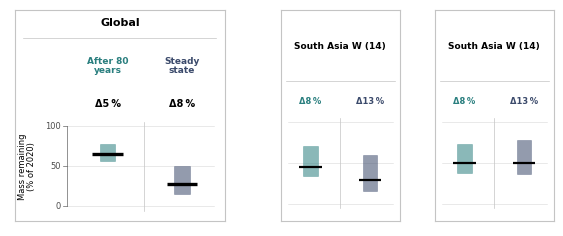

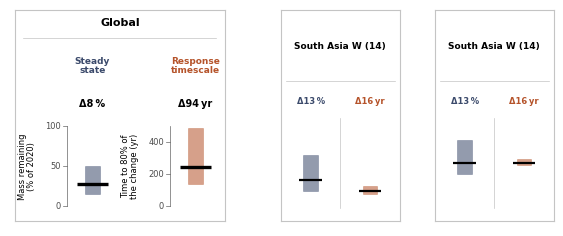

In [12]:
# test: the Global subplot and one region, as for the pies in the GMIP3-comm notebook
for variant in ['y80', 'tau']:
    fig = plt.figure(figsize=(7, 2.2))
    ax = fig.add_axes([0.02, 0.02, 0.3, 0.96])
    reg_subplot(reg='All', ax=ax, variant=variant, mode='abs', title='Global', big=True)
    ax = fig.add_axes([0.40, 0.02, 0.17, 0.96])
    reg_subplot(reg='14', ax=ax, variant=variant, mode='abs', title='South Asia W\u00a0(14)')
    ax = fig.add_axes([0.62, 0.02, 0.17, 0.96])
    reg_subplot(reg='14', ax=ax, variant=variant, mode='diff', title='South Asia W\u00a0(14)')
    plt.show()

## 3. Global subplot with legend

All explanations that are not part of the subplot itself are given by arrows in the legend (the definitions go to the figure caption).

In [13]:
def global_subplot_with_legend(fig, rect, variant='y80', mode='abs', style=None):
    if style is None:
        style = subplot_style
    ax_patch = fig.add_axes(rect, zorder=6)
    ax_patch.set_xlim(0, 1)
    ax_patch.set_ylim(0, 1)
    ax_patch.set_xticks([])
    ax_patch.set_yticks([])
    for sp in ax_patch.spines.values():
        sp.set_color('#1f4e5f')
        sp.set_linewidth(1.0)

    x0, y0, w, h = rect
    gy, gh = (0.46, 0.52) if style == 'range' else (0.50, 0.48)   # CL: the 'dots' legend needs more space
    ax_glob = fig.add_axes([x0 + 0.03 * w, y0 + gy * h, 0.94 * w, gh * h], zorder=7)
    reg_subplot(reg='All', ax=ax_glob, variant=variant, mode=mode, title='Global', big=True, style=style)
    for sp in ax_glob.spines.values():   # CL: no second frame inside the legend box
        sp.set_visible(False)

    # text of the legend (the definitions are given in the figure caption)
    pd_bin = pd_ss.loc[(pd_ss.temp_ch_ipcc >= temp_bin[0]) & (pd_ss.temp_ch_ipcc <= temp_bin[1])]
    n_scen = len(pd_bin.groupby(['gcm', 'period_scenario']))
    if temp_bin[1] == 4.0:
        np.testing.assert_allclose(n_scen, 31)
    # CL: the sentence on the climate scenarios ("each global model: median over the 31 climate scenarios ...") is
    # removed from the figure (no space at 6 pt), it must be in the caption (it is already in the suggested caption)
    txt_line = "median of the four global\nmodels' medians" + (' (= 0)' if mode == 'diff' else '')

    fs_leg = 6.0                                    # CL: printed size
    arrow = dict(arrowstyle='-|>', color='k', lw=0.5, shrinkA=0, shrinkB=0, mutation_scale=5)
    if style == 'range':
        # dummy subplot with arrows
        col = col_80 if variant == 'y80' else col_ss
        ax_patch.add_patch(Rectangle((0.075, 0.13), 0.05, 0.16, fc=col, ec=col, alpha=0.55, lw=0.4))
        ax_patch.plot([0.05, 0.15], [0.21, 0.21], color='k', lw=2.2, solid_capstyle='butt')
        ax_patch.text(0.10, 0.36, '\u0394', fontsize=7.5, weight='bold', ha='center', va='center')
        ax_patch.annotate('', xy=(0.135, 0.36), xytext=(0.22, 0.36), arrowprops=arrow)
        ax_patch.text(0.235, 0.36, 'median difference of the four\nglobal models to their median', fontsize=fs_leg,
                      va='center', linespacing=1.05)
        ax_patch.annotate('', xy=(0.13, 0.26), xytext=(0.22, 0.235), arrowprops=arrow)
        ax_patch.text(0.235, 0.235, "total range of the four global\nmodels' medians", fontsize=fs_leg, va='center',
                      linespacing=1.05)
        ax_patch.annotate('', xy=(0.155, 0.21), xytext=(0.22, 0.11), arrowprops=arrow)
        ax_patch.text(0.235, 0.11, txt_line, fontsize=fs_leg, va='center', linespacing=1.05)
    else:
        ax_patch.plot([0.05, 0.13], [0.445, 0.445], color='0.15', lw=2.2, solid_capstyle='butt')
        ax_patch.text(0.16, 0.445, txt_line, fontsize=fs_leg, va='center', linespacing=1.05)
        ax_patch.text(0.05, 0.355, 'Global models\n(in median)', fontsize=fs_leg, weight='bold', va='center',
                      linespacing=1.0)
        ax_patch.text(0.53, 0.355, 'Regional models\n(not in median)', fontsize=fs_leg, weight='bold', va='center',
                      linespacing=1.0)
        for k, m in enumerate(global_models):
            ax_patch.plot([0.07], [0.28 - 0.052 * k], 'o', ms=3.5, mfc=dict_model_col[m], mec='0.15', mew=0.3)
            ax_patch.text(0.11, 0.28 - 0.052 * k, m, fontsize=fs_leg, va='center')
        for k, m in enumerate(regional_models):
            ax_patch.plot([0.55], [0.28 - 0.052 * k], 'D', ms=3.0, mfc=dict_model_col[m], mec='0.15', mew=0.3)
            ax_patch.text(0.59, 0.28 - 0.052 * k, m, fontsize=fs_leg, va='center')
        ax_patch.text(0.05, 0.045, '\u0394: median difference of the four global\nmodels to their median',
                      fontsize=fs_leg, va='center', linespacing=1.05)

## 4. The worldmap

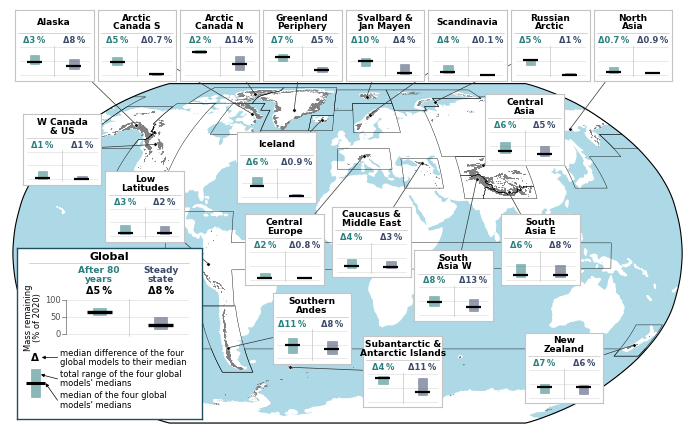

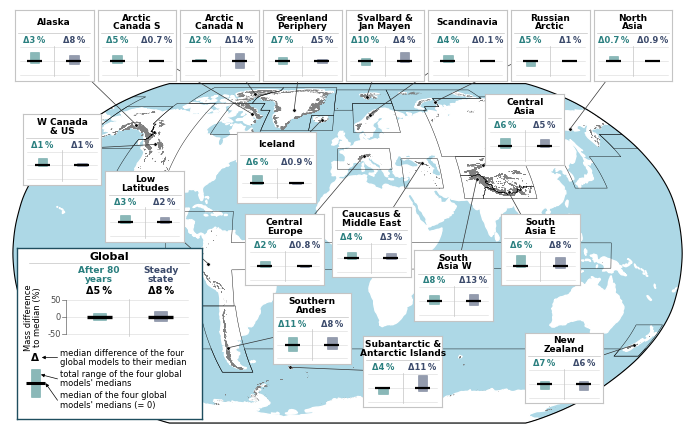

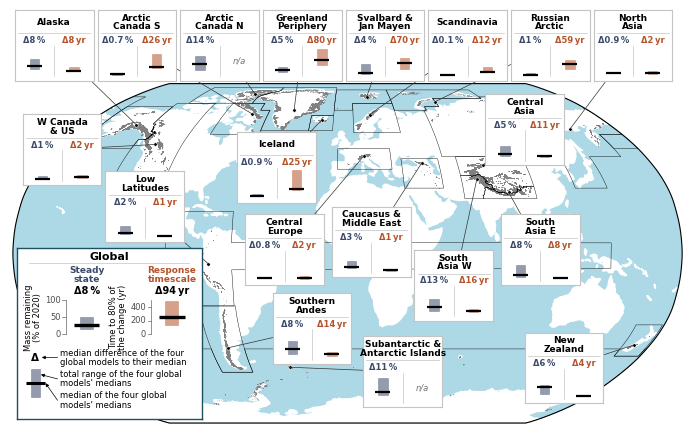

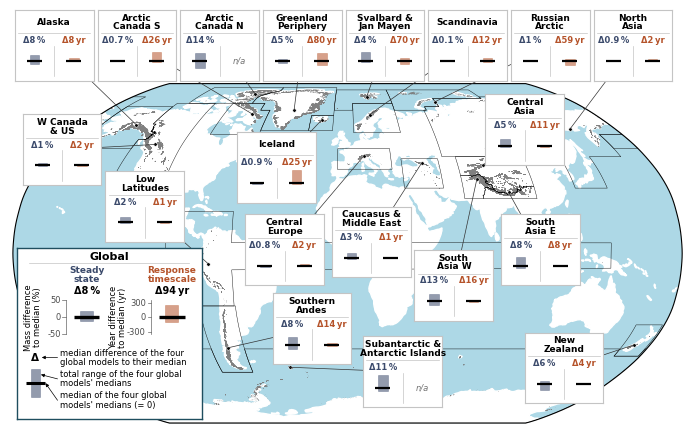

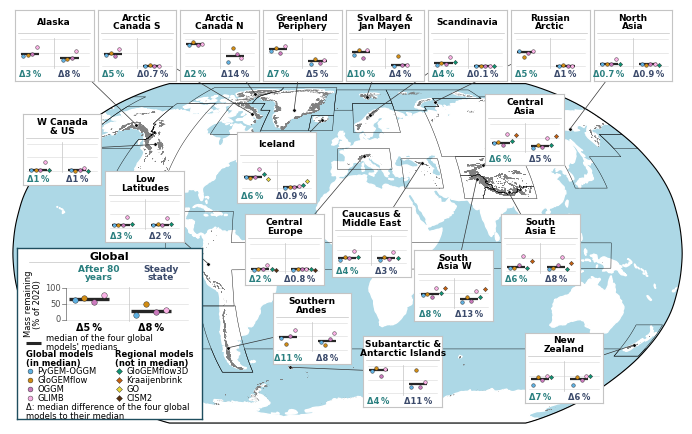

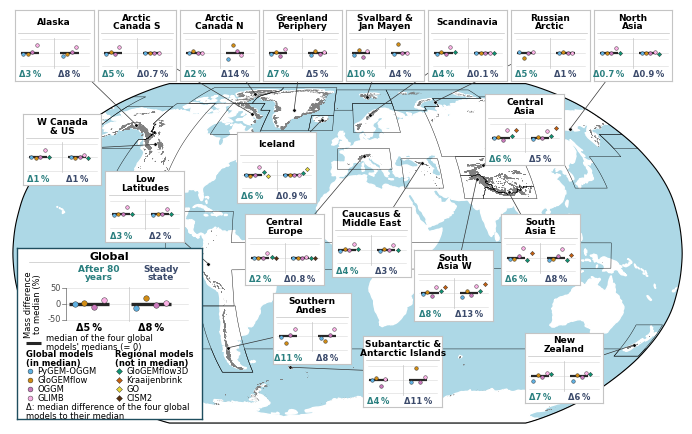

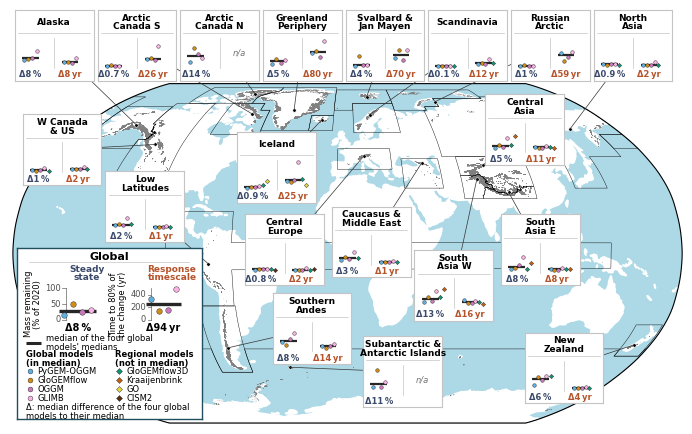

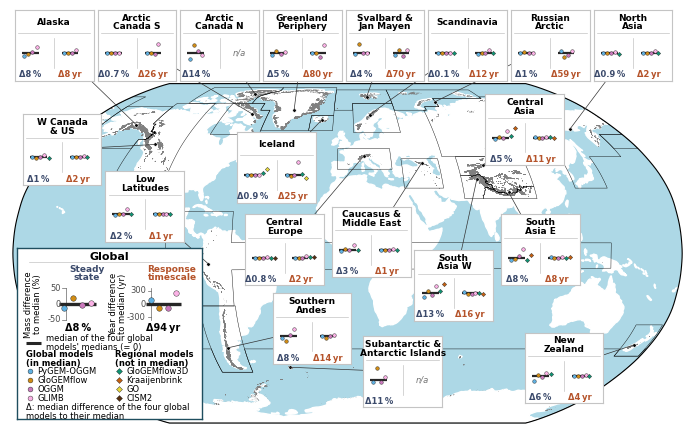

In [14]:
variant_name = {'y80': '80yr_vs_steady_state', 'tau': 'steady_state_vs_resp_time'}
mode_name = {'abs': 'absolute', 'diff': 'difference'}
cm = 1 / 2.54

# the version with all glacier models as dots is an additional option for the discussion
styles = [subplot_style] + (['dots'] if also_dots and subplot_style != 'dots' else [])

for style in styles:
    for variant in variants:
        for mode in modes:
            # CL: printed size (17 x 10.6 cm), see fig_w_cm; the map fills the width, the strip above holds the first row of boxes
            fig = plt.figure(figsize=(fig_w_cm * cm, fig_h_cm * cm))

            # Add background image
            ax_background = fig.add_axes([0, 0, 1, map_h_cm / fig_h_cm], projection=ccrs.Robinson())
            ax_background.patch.set_facecolor('lightblue')
            ax_background.get_yaxis().set_visible(False)
            ax_background.get_xaxis().set_visible(False)
            ax_background.add_feature(cartopy.feature.LAND, color='white')

            # Add RGI glacier dots and RGI regions (as in the GMIP3-comm worldmap)
            if add_rgi_glaciers:
                # CL: s is in pt^2 of the printed figure (before: 0.25 on the 40.6 cm wide canvas, i.e. ~0.04 printed);
                # rasterized to keep the pdf small (Copernicus: max. 2 MB per pdf figure) -- TODO check the look
                ax_background.scatter(df_rgi6g.CenLon.values, df_rgi6g.CenLat.values,
                                      facecolor='grey', s=0.05, alpha=0.7, linewidths=0, edgecolor='grey',
                                      transform=ccrs.PlateCarree(), rasterized=True)
            if add_rgi_regions:
                shape_feature = ShapelyFeature(Reader(rgi_regions_fn).geometries(), ccrs.Robinson(), alpha=1,
                                               facecolor='None', linewidth=0.3, edgecolor='k')
                ax_background.add_feature(shape_feature)

            # Add the global subplot with the legend
            global_subplot_with_legend(fig, [glob_rect_cm[0] / fig_w_cm, glob_rect_cm[1] / fig_h_cm,
                                             glob_rect_cm[2] / fig_w_cm, glob_rect_cm[3] / fig_h_cm],
                                       variant=variant, mode=mode, style=style)

            # Add the subplots of the regions
            for reg, (xc_cm, yc_cm) in box_pos_cm.items():
                lon, lat = reg_lonlat[reg]
                x_reg, y_reg = ccrs.Robinson().transform_point(lon, lat, ccrs.PlateCarree())
                # line from the subplot to the region, behind the subplot
                fig.add_artist(ConnectionPatch(xyA=(x_reg, y_reg), coordsA=ax_background.transData,
                                               xyB=(xc_cm / fig_w_cm, yc_cm / fig_h_cm), coordsB=fig.transFigure,
                                               color='0.2', lw=0.5, zorder=3))
                ax_background.plot(lon, lat, 'o', ms=2.5, mfc='k', mec='w', mew=0.4, transform=ccrs.PlateCarree(), zorder=4)

                ax = fig.add_axes([(xc_cm - box_w_cm / 2) / fig_w_cm, (yc_cm - box_h_cm / 2) / fig_h_cm,
                                   box_w_cm / fig_w_cm, box_h_cm / fig_h_cm], zorder=6)
                if show_numbers:
                    title = f'{reg_names_lines[reg]}\u00a0({reg})'
                else:
                    title = reg_names_lines[reg]       # CL: keep the line breaks
                reg_subplot(reg=reg, ax=ax, variant=variant, mode=mode, title=title, style=style)

            # plotting with a transform changes the extent of the map, so set it back to the whole globe
            ax_background.set_global()

            fn_out = f'{fig_dir}/PartB_worldmap_{variant_name[variant]}_{mode_name[mode]}_{style}'
            plt.savefig(fn_out + '.png', dpi=300)   # CL: 300 dpi at the printed size (Copernicus requirement)
            plt.savefig(fn_out + '.pdf')
            plt.show()

## Suggested captions (LaTeX)

```latex
% variant y80
\caption{Glacier model differences in the transient and steady-state mass response of the four global glacier models
(PyGEM-OGGM, GloGEMflow, OGGM, GLIMB) for the 19 RGI regions and globally, for global warming levels between
2.0$^\circ$C and 4.0$^\circ$C (31 climate scenarios). Left: glacier mass remaining after 80 simulation years
(mean of years 70 to 89), right: at steady state (mean of the last 100 simulation years), both as percentage of the
2020 mass. The bars show the total range of the four global models' medians (each model: median over the 31 climate scenarios),
the black lines show the median of these four medians (per climate scenario, then median over the 31 scenarios). The number gives the median glacier model difference $\Delta$, i.e., the median of the
absolute differences between each global model and the median of the four global models over all models and climate scenarios.}

% variant tau
\caption{As Fig.~\ref{...}, but left: steady-state mass, right: response timescale (time until 80\,\% of the total mass
change has occurred, counted from the simulation start). \TODO{No estimate (n/a) where more than 25\,\% of the experiments of one of the global models do not reach the required mass change.}}
```